<a href="https://colab.research.google.com/github/GeorgiyScherbakov/useful_programs/blob/main/pages/solutions/02_sol_colab/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
# Colab Intro

# Sumowanie ciągu geometrycznego

Rozważmy ciąg geometryczny o pierwszym wyrazie \(a\) i ilorazie \(r\):
\[
a,\; ar,\; ar^2,\; \dots,\; ar^{n-1}.
\]
Suma pierwszych \(n\) wyrazów tego ciągu to:
\[
S_n = a + ar + ar^2 + \dots + ar^{n-1}.
\]

Dowód klasyczny (dla \(r \neq 1\)):

Zapiszemy sumę i pomnożymy ją przez \(r\):
\[
\begin{aligned}
S_n &= a + ar + ar^2 + \dots + ar^{n-1},\\
rS_n &= ar + ar^2 + \dots + ar^n.
\end{aligned}
\]
Odejmując:
\[
S_n - rS_n = a - ar^n \quad\Rightarrow\quad S_n(1-r) = a(1-r^n),
\]
stąd dla \(r \neq 1\):
\[
\boxed{\,S_n = \dfrac{a(1-r^n)}{1-r}\,}.
\]

Dla \(r = 1\) mamy trywialnie:
\[
\boxed{\,S_n = an\, }.
\]

Przykład:
dla \(a=3\), \(r=2\), \(n=5\) otrzymujemy
\[
S_5 = \frac{3(1-2^5)}{1-2} = 93.
\]

In [22]:
result = 2 + 2
print(result)

4


In [23]:
import math
result = math.pi ** math.pi
print(result)

36.4621596072079


In [24]:
suma_kwadratow = sum(k**2 for k in range(1, 101))
print(suma_kwadratow)

338350


In [25]:
# Obliczamy sumę kwadratów od 1 do 100 i zapisujemy wynik do pliku w /content
import os

suma_kwadratow = sum(k**2 for k in range(1, 101))

# Ścieżka, gdzie zapisujemy w Colabie (aktualny katalog roboczy to /content)
filepath = '/content/colab_wynik.txt'

with open(filepath, 'w') as f:
    f.write(str(suma_kwadratow))

print(f"Zapisano wartość {suma_kwadratow} do pliku: {filepath}")
print("Czy plik istnieje?", os.path.exists(filepath))

# Pokażemy zawartość pliku aby zweryfikować zapis
with open(filepath, 'r') as f:
    print("Zawartość pliku:", f.read())

# --- Opcjonalnie: zapisz też do Google Drive (wymaga pozwolenia użytkownika) ---
# from google.colab import drive
# drive.mount('/content/drive')  # zaloguj się i nadaj uprawnienia
# drive_path = '/content/drive/MyDrive/colab_wynik.txt'
# with open(drive_path, 'w') as f:
#     f.write(str(suma_kwadratow))
# print(f"Zapisano kopię do Drive: {drive_path}")

Zapisano wartość 338350 do pliku: /content/colab_wynik.txt
Czy plik istnieje? True
Zawartość pliku: 338350


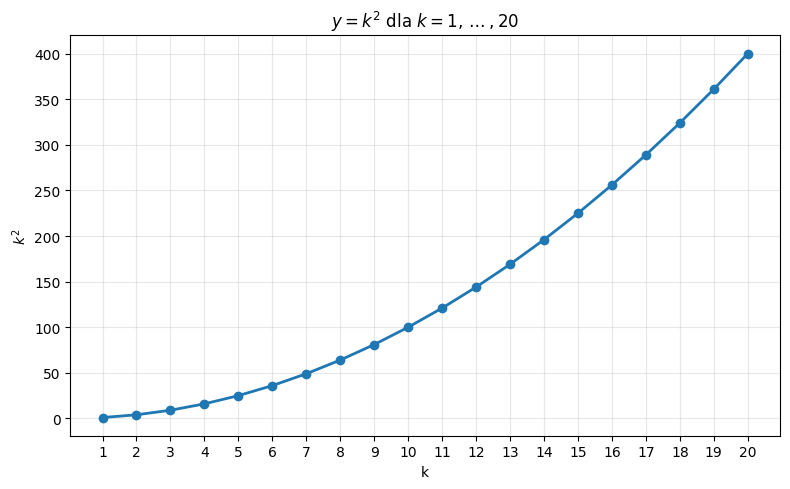

Zapisano wykres do: /content/wykres.png


In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Dane
k = np.arange(1, 21)
y = k**2

# Rysowanie wykresu
plt.figure(figsize=(8, 5))
plt.plot(k, y, '-o', color='C0', markersize=6, linewidth=2)
plt.title(r'$y = k^2$ dla $k = 1, \dots, 20$')
plt.xlabel('k')
plt.ylabel(r'$k^2$')
plt.xticks(k)
plt.grid(alpha=0.3)
plt.tight_layout()

# Zapis do pliku (w Colabie /content)
save_path = '/content/wykres.png'
plt.savefig(save_path, dpi=150)
plt.show()

print(f'Zapisano wykres do: {save_path}')

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# 1. Konfiguracja parametrów wahadła
g = 9.81        # Przyspieszenie ziemskie (m/s^2)
L = 2.0         # Długość nici (m)
theta_max = np.radians(45) # Maksymalne wychylenie (amplituda)

# Czas trwania animacji
fps = 30
duration = 5    # sekundy
frames = fps * duration
t = np.linspace(0, duration, frames)

# Przybliżone równanie ruchu dla małych/średnich wychyleń: theta(t) = theta_max * cos(omega * t)
omega = np.sqrt(g / L)
theta = theta_max * np.cos(omega * t)

# Współrzędne x, y końca wahadła
x = L * np.sin(theta)
y = -L * np.cos(theta)

# 2. Tworzenie wykresów i animacji
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-L * 1.2, L * 1.2)
ax.set_ylim(-L * 1.2, L * 1.2)
ax.set_aspect('equal')
ax.grid(True)
ax.set_title("Animacja Wahadła Fizycznego")

# Elementy graficzne: linia (nić) i kropka (ciężarek)
line, = ax.plot([], [], 'o-', lw=3, markersize=12, color='royalblue')
trace, = ax.plot([], [], '--', lw=1, color='orange', alpha=0.5)
x_trace, y_trace = [], []

def init():
    line.set_data([], [])
    trace.set_data([], [])
    return line, trace

def animate(i):
    # Aktualizacja pozycji nici i ciężarka
    this_x = [0, x[i]]
    this_y = [0, y[i]]
    line.set_data(this_x, this_y)

    # Dodanie śladu ruchu
    x_trace.append(x[i])
    y_trace.append(y[i])
    if len(x_trace) > 30:  # ograniczamy długość śladu
        x_trace.pop(0)
        y_trace.pop(0)
    trace.set_data(x_trace, y_trace)

    return line, trace

# Tworzenie obiektu animacji
ani = animation.FuncAnimation(fig, animate, init_func=init,
                              frames=frames, interval=1000/fps, blit=True)

# 3. Zapis do pliku video.mp4
# Wymaga zainstalowanego ffmpeg w środowisku Colab (zazwyczaj jest domyślnie)
print("Zapisywanie pliku wideo...")
output_file = 'video.mp4'
writer = animation.FFMpegWriter(fps=fps, metadata=dict(artist='Me'), bitrate=1800)
ani.save(output_file, writer=writer)
print(f"Zapisano animację jako: {output_file}")

plt.close(fig)

# 4. Osadzenie i wyświetlenie wideo w notebooku
HTML(ani.to_html5_video())

Zapisywanie pliku wideo...
Zapisano animację jako: video.mp4


Wczytywanie wideo z pliku: /content/video.mp4...
Generowanie pliku GIF (zapis w bieżącym katalogu roboczym)...
Sukces! Plik GIF został zapisany jako: /content/video.gif


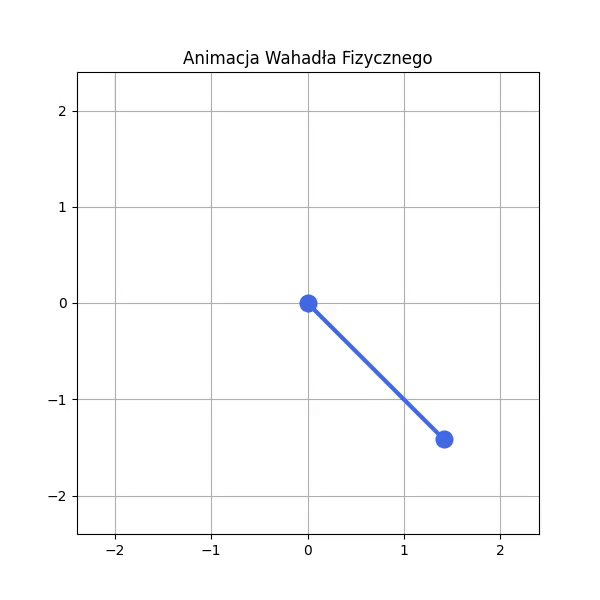

In [28]:
import imageio.v3 as iio
import os
from IPython.display import Image, display

# 1. Definicja ścieżek wejściowej i wyjściowej
input_video = 'video.mp4'
output_gif = 'video.gif'

# Sprawdzenie, czy plik wejściowy istnieje
if not os.path.exists(input_video):
    raise FileNotFoundError(f"Nie znaleziono pliku {input_video}! Upewnij się, że został wcześniej wygenerowany.")

print(f"Wczytywanie wideo z pliku: {os.path.abspath(input_video)}...")

# 2. Wczytanie klatek wideo oraz metadanych (w tym liczby klatek na sekundę - fps)
# imageio.imread reads the frames; we can also use metadata to extract fps
frames = []
fps = 30 # domyślna wartość zapasowa, gdyby metadane nie podawały fps

# Odczyt klatek za pomocą imageio (v3)
for frame in iio.imiter(input_video):
    frames.append(frame)

# Pobranie metadanych wideo (np. fps)
try:
    meta = iio.improps(input_video)
    # jeśli metadane zawierają informację o czasie/klatkach, możemy dostosować duration
    # duration dla pojedynczej klatki w sekundach = 1 / fps
except Exception:
    pass

# Czas trwania jednej klatki w milisekundach (standardowo przyjmujemy 30 fps -> ~33ms)
duration_ms = 1000 / 30

# 3. Zapis do pliku GIF
print(f"Generowanie pliku GIF (zapis w bieżącym katalogu roboczym)...")
iio.imwrite(output_gif, frames, duration=duration_ms, loop=0) # loop=0 oznacza zapętlenie w nieskończoność

# 4. Sprawdzenie i potwierdzenie ścieżki zapisu
absolute_path = os.path.abspath(output_gif)
print(f"Sukces! Plik GIF został zapisany jako: {absolute_path}")

# 5. Podgląd wygenerowanego pliku GIF bezpośrednio w notebooku
display(Image(filename=output_gif))

Pomyślnie zapisano wykres do: /content/parametric_curve.png


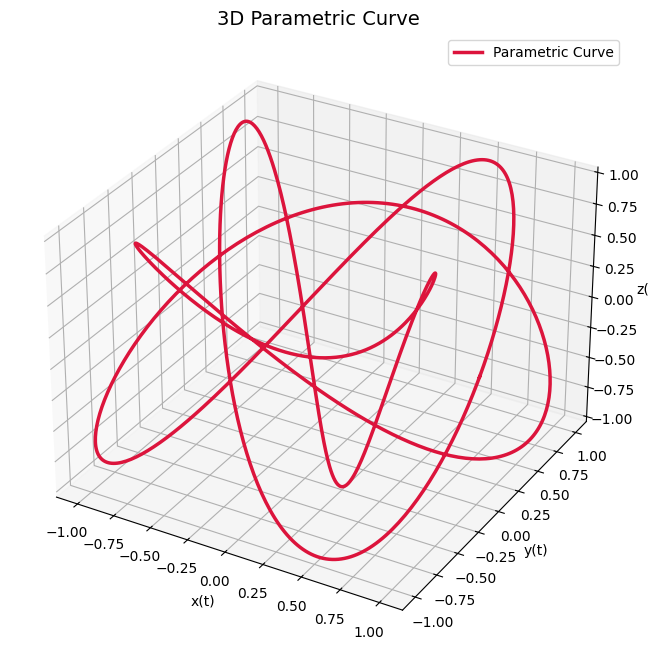

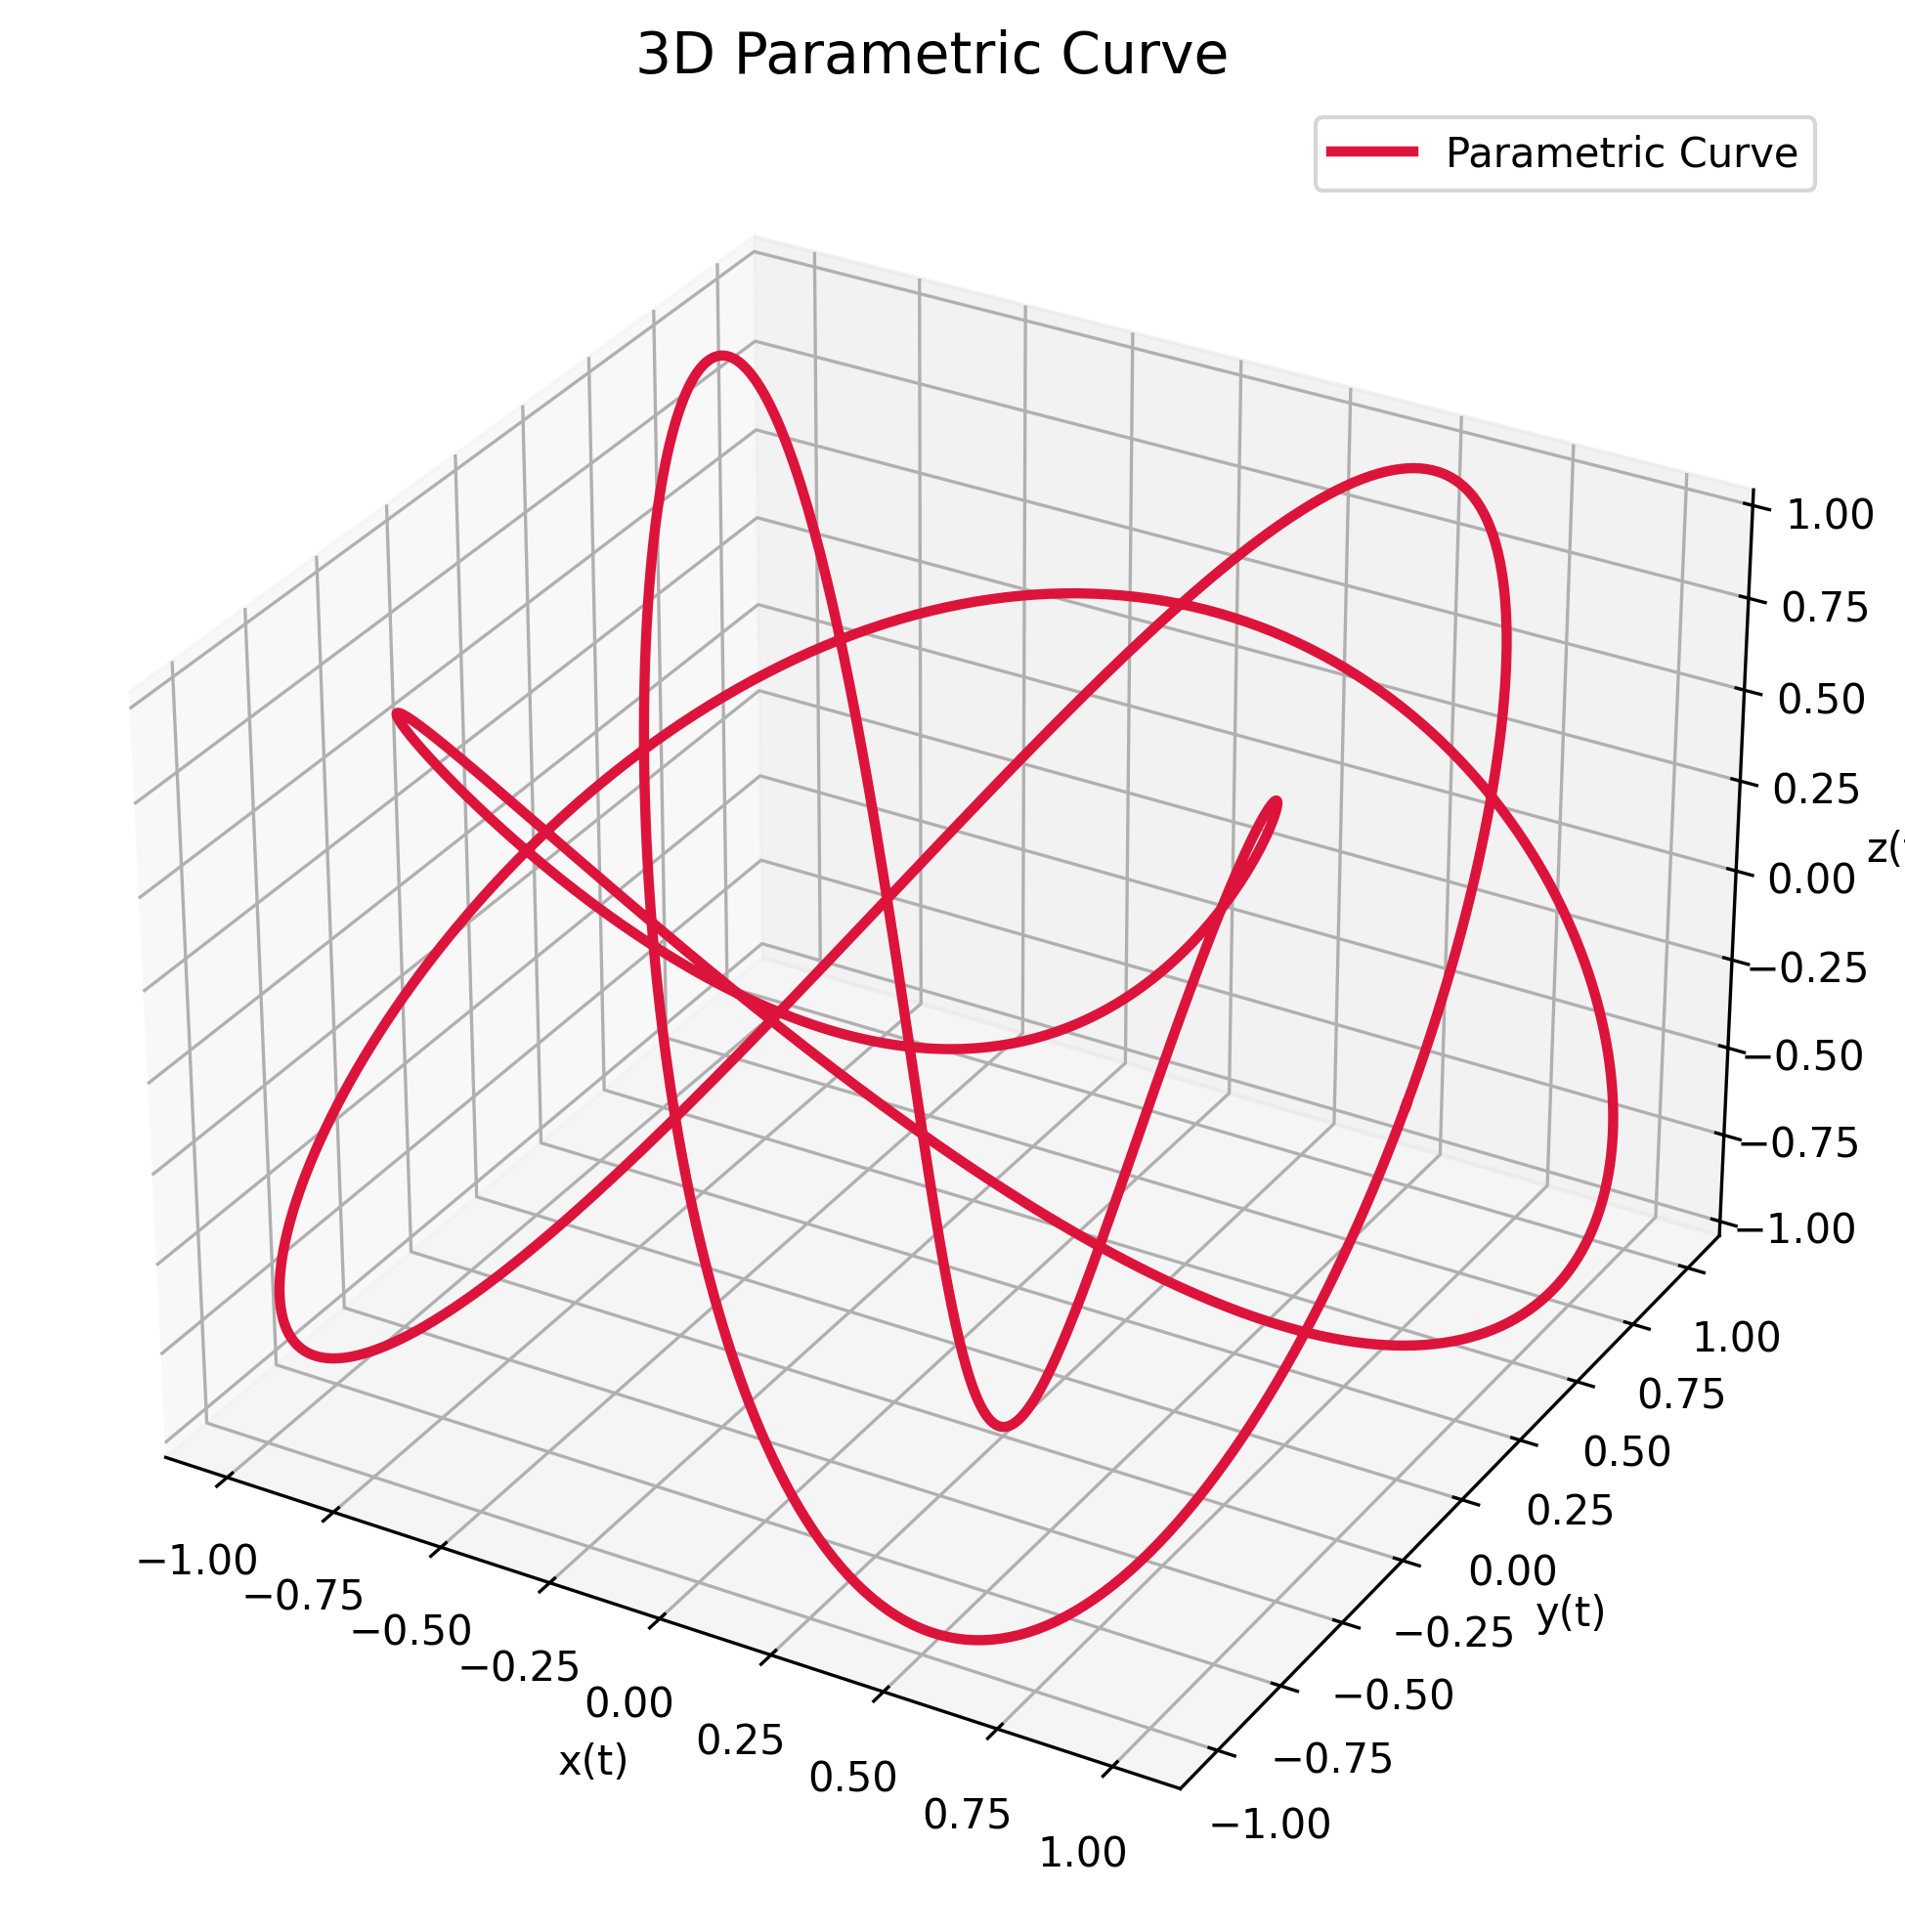

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import Image, display
import os

# Parametry dla krzywej Lissajous 3D
a, b, c = 3, 4, 5
delta, phi = np.pi / 2, 0

t = np.linspace(0, 2 * np.pi, 1000)

# Równania parametryczne krzywej Lissajous 3D
x = np.sin(a * t + delta)
y = np.sin(b * t + phi)
z = np.sin(c * t)

# Tworzenie wykresu 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Parametric Curve", color='crimson', lw=2.5)
ax.set_title("3D Parametric Curve", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

# Zapis pliku do parametric_curve.png
output_image = 'parametric_curve.png'
plt.savefig(output_image, dpi=300, bbox_inches='tight')

absolute_path = os.path.abspath(output_image)
print(f"Pomyślnie zapisano wykres do: {absolute_path}")

# Wyświetlenie i zamknięcie figury
plt.show()
plt.close(fig)

# Podgląd zapisanego obrazu
display(Image(filename=output_image))